# RQ1 — Route–airline clustering

**Research question:** Do route–airline combinations with similar operational characteristics exhibit similar arrival-delay patterns?

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

RANDOM_SEED = 42
MIN_FLIGHTS = 30
N_CLUSTERS = 7
KEYS = ["origin", "dest", "op_unique_carrier"]


## Load cleaned flights and prepare operational features

In [14]:
df = load_flights(CLEAN_PARQUET)

TRAIN_MONTHS = list(range(1, 7))

df = df.loc[df["month"].isin(TRAIN_MONTHS)].copy()

print(f"Training dataset: {len(df):,} rows")

flights = df.loc[
    (df["cancelled"] == 0)
    & (df["diverted"] == 0)
    & (df["distance"] > 0)
    & (df["crs_elapsed_time"] > 0)
].copy()

dep_time = flights["crs_dep_time"]
valid_time = (
    dep_time.notna()
    & dep_time.between(0, 2400)
    & ((dep_time % 100) < 60)
)
flights = flights.loc[valid_time].copy()
flights["dep_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)

flights["evening"] = (flights["dep_hour"] >= 18).astype(int)
flights["morning"] = flights["dep_hour"].between(5, 11).astype(int)
flights["afternoon"] = flights["dep_hour"].between(12, 17).astype(int)
flights["evening_night"] = ((flights["dep_hour"] >= 18) | (flights["dep_hour"] < 5)).astype(int)
flights["weekend"] = flights["day_of_week"].isin([6, 7]).astype(int)
flights["delayed_15"] = (flights["arr_delay"] >= 15).where(flights["arr_delay"].notna()).astype("Int64")

assert (flights[["morning", "afternoon", "evening_night"]].sum(axis=1) == 1).all()
print(f"Eligible completed flights: {len(flights):,}")


Training dataset: 3,461,313 rows
Eligible completed flights: 3,403,472


## Aggregate to one row per route–airline combination

Groups eligible flights by origin, destination and airline. Retains combinations with at least 30 flights.

In [4]:
route_data_all = (
    flights.groupby(KEYS, observed=True)
    .agg(
        n_flights=("distance", "size"),
        mean_distance=("distance", "mean"),
        mean_duration=("crs_elapsed_time", "mean"),
        evening_share=("evening", "mean"),
        morning_share=("morning", "mean"),
        afternoon_share=("afternoon", "mean"),
        evening_night_share=("evening_night", "mean"),
        weekend_share=("weekend", "mean"),
    )
    .reset_index()
)

training_start = pd.Timestamp(2024, min(TRAIN_MONTHS), 1)
training_end = pd.Timestamp(2024, max(TRAIN_MONTHS) + 1, 1)

n_weeks = (training_end - training_start).days / 7

route_data_all["flights_per_week"] = route_data_all["n_flights"] / n_weeks

route_data = route_data_all.loc[
    route_data_all["n_flights"] >= MIN_FLIGHTS
].copy()
route_data["log_flights_per_week"] = np.log1p(route_data["flights_per_week"])

print(f"Training period: {n_weeks:.2f} weeks")
print(f"Before threshold: {len(route_data_all):,} combinations")
print(f"After threshold: {len(route_data):,} combinations")

display(
    route_data[
        KEYS + ["n_flights", "flights_per_week"]
    ].head(10)
)


Training period: 26.00 weeks
Before threshold: 12,170 combinations
After threshold: 9,972 combinations


,origin,dest,op_unique_carrier,n_flights,flights_per_week
0,ABE,ATL,9E,503,19.346154
1,ABE,BNA,G4,51,1.961538
2,ABE,CLT,OH,537,20.653846
3,ABE,DEN,G4,51,1.961538
4,ABE,FLL,G4,55,2.115385
6,ABE,MLB,G4,51,1.961538
7,ABE,MYR,G4,73,2.807692
8,ABE,ORD,OO,297,11.423077
9,ABE,PGD,G4,90,3.461538
10,ABE,PIE,G4,125,4.807692


## Feature choice and correlation

Decides which characteristics K-means should use to determine whether two route–airline combinations are similar.

In [5]:
corr = route_data[
    [
        "mean_distance",
        "mean_duration",
        "log_flights_per_week",
        "evening_share",
        "weekend_share"
    ]
].corr()

display(corr.round(3))


,mean_distance,mean_duration,log_flights_per_week,evening_share,weekend_share
mean_distance,1.000,0.984,-0.088,0.033,0.078
mean_duration,0.984,1.000,-0.082,0.028,0.071
log_flights_per_week,-0.088,-0.082,1.000,0.045,-0.221
evening_share,0.033,0.028,0.045,1.000,-0.061
weekend_share,0.078,0.071,-0.221,-0.061,1.000


## Feature sets and K selection

Model A uses evening share; Model B separates morning and evening/night schedules. Both use distance, log flights per week, and weekend share.


In [6]:
FEATURES_A = [
    "mean_distance",
    "log_flights_per_week",
    "evening_share",
    "weekend_share"
]

FEATURES_B = [
    "mean_distance",
    "log_flights_per_week",
    "morning_share",
    "evening_night_share",
    "weekend_share"
]
scaler_a = StandardScaler()
scaler_b = StandardScaler()

X_a = scaler_a.fit_transform(route_data[FEATURES_A])
X_b = scaler_b.fit_transform(route_data[FEATURES_B])

def evaluate_k(X, model_name):
    rows = []
    for k in range(2, 11):
        labels = KMeans(
            n_clusters=k,
            random_state=RANDOM_SEED,
            n_init=10
        ).fit_predict(X)

        rows.append({
            "model": model_name,
            "k": k,
            "davies_bouldin": davies_bouldin_score(X, labels),
            "silhouette": silhouette_score(
                X,
                labels,
                sample_size=min(3000, len(X)),
                random_state=RANDOM_SEED
            ),
        })
    return pd.DataFrame(rows)

evaluation_a = evaluate_k(X_a, "A_evening_only")
evaluation_b = evaluate_k(X_b, "B_time_of_day")

print("Model A — K evaluation")
display(evaluation_a.round(3))

print("Model B — K evaluation")
display(evaluation_b.round(3))


Model A — K evaluation


,model,k,davies_bouldin,silhouette
0,A_evening_only,2,1.678,0.244
1,A_evening_only,3,1.336,0.271
2,A_evening_only,4,1.171,0.291
3,A_evening_only,5,1.016,0.317
4,A_evening_only,6,0.961,0.316
5,A_evening_only,7,0.932,0.320
6,A_evening_only,8,0.985,0.296
7,A_evening_only,9,1.020,0.283
8,A_evening_only,10,1.055,0.263


Model B — K evaluation


,model,k,davies_bouldin,silhouette
0,B_time_of_day,2,1.846,0.242
1,B_time_of_day,3,1.518,0.237
2,B_time_of_day,4,1.411,0.269
3,B_time_of_day,5,1.228,0.284
4,B_time_of_day,6,1.117,0.296
5,B_time_of_day,7,1.071,0.300
6,B_time_of_day,8,1.162,0.246
7,B_time_of_day,9,1.174,0.236
8,B_time_of_day,10,1.111,0.247


## K-Means cluster profiles


In [7]:
model_a = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
model_b = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)

route_a = route_data.copy()
route_b = route_data.copy()

route_a["cluster"] = model_a.fit_predict(X_a)
route_b["cluster"] = model_b.fit_predict(X_b)

print("Model A: cluster sizes and characteristics")

display(
    route_a.groupby("cluster")[
        ["mean_distance", "n_flights", "evening_share", "weekend_share"]
    ].mean().round(3)
)

display(
    route_a["cluster"].value_counts().sort_index().rename("n_routes")
)

print("Model B: cluster sizes and characteristics")

display(
    route_b.groupby("cluster")[
        ["mean_distance", "n_flights", "morning_share",
         "afternoon_share", "evening_night_share", "weekend_share"]
    ].mean().round(3)
)

display(
    route_b["cluster"].value_counts().sort_index().rename("n_routes")
)


Model A: cluster sizes and characteristics


,mean_distance,n_flights,evening_share,weekend_share
cluster,,,,
0,629.916992,662.963,0.263,0.268
1,933.914001,65.936,0.137,0.474
2,2096.639893,329.921,0.146,0.286
3,701.304993,168.905,0.058,0.282
4,1108.655029,48.060,0.065,0.904
5,875.773987,57.544,0.148,0.084
6,1032.785034,141.410,0.749,0.285


cluster
0    3349
1     590
2    1147
3    3310
4     116
5     371
6    1089
Name: n_routes, dtype: int64

Model B: cluster sizes and characteristics


,mean_distance,n_flights,morning_share,afternoon_share,evening_night_share,weekend_share
cluster,,,,,,
0,1004.007019,156.545,0.090,0.171,0.739,0.277
1,2204.565918,369.595,0.477,0.344,0.179,0.285
2,637.653015,630.258,0.424,0.345,0.232,0.269
3,818.073975,149.047,0.803,0.161,0.036,0.271
4,1111.316040,47.658,0.384,0.550,0.066,0.908
5,757.353027,128.229,0.178,0.727,0.095,0.262
6,923.117004,70.702,0.397,0.455,0.148,0.483


cluster
0    1198
1     915
2    3684
3    1695
4     114
5    1819
6     547
Name: n_routes, dtype: int64

## Compare arrival-delay behaviour **after** clustering

We define a late arrival as `arr_delay >= 15`. Each route–airline combination gets a delay rate. We investigate whether routes grouped by operational characteristics actually experience similar delays.

In [8]:
delay_stats = (
    flights.groupby(KEYS, observed=True)
    .agg(
        delay_rate=("delayed_15", "mean"),
        n_valid_delays=("arr_delay", "count"),
        mean_arr_delay=("arr_delay", "mean"),
        median_arr_delay=("arr_delay", "median"),
    )
    .reset_index()
)

def delay_summary(routes):
    merged = routes[KEYS + ["cluster", "n_flights"]].merge(
        delay_stats, on=KEYS, how="left", validate="one_to_one"
    )
    summary = merged.groupby("cluster").agg(
        n_routes=("delay_rate", "size"),
        avg_delay_rate=("delay_rate", "mean"),
        avg_arr_delay=("mean_arr_delay", "mean"),
        median_arr_delay=("median_arr_delay", "median"),
    )
    weighted = merged.groupby("cluster").apply(
        lambda g: np.average(g["delay_rate"], weights=g["n_valid_delays"]),
        include_groups=False,
    )
    summary["weighted_delay_rate"] = weighted
    overall = merged["delay_rate"].mean()
    by_cluster = merged.groupby("cluster")["delay_rate"]
    ss_between = (by_cluster.size() * (by_cluster.mean() - overall) ** 2).sum()
    ss_total = ((merged["delay_rate"] - overall) ** 2).sum()
    eta_sq = ss_between / ss_total
    return merged, summary, eta_sq

route_with_delays_a, cluster_delays_a, eta_a = delay_summary(route_a)
route_with_delays_b, cluster_delays_b, eta_b = delay_summary(route_b)

print("Model A — delay patterns")
display(cluster_delays_a.round(3))
print(f"Model A eta-squared: {eta_a:.4f} ({100*eta_a:.2f}%)")
print("Model B — delay patterns")
display(cluster_delays_b.round(3))
print(f"Model B eta-squared: {eta_b:.4f} ({100*eta_b:.2f}%)")


Model A — delay patterns


,n_routes,avg_delay_rate,avg_arr_delay,median_arr_delay,weighted_delay_rate
cluster,,,,,
0,3349,0.22,8.502,-5.00,0.222
1,590,0.222,8.448,-7.00,0.227
2,1147,0.225,6.558,-5.00,0.220
3,3310,0.2,7.301,-7.00,0.197
4,116,0.271,10.725,-1.75,0.271
5,371,0.202,7.327,-8.00,0.196
6,1089,0.277,15.418,-4.00,0.272


Model A eta-squared: 0.0594 (5.94%)
Model B — delay patterns


,n_routes,avg_delay_rate,avg_arr_delay,median_arr_delay,weighted_delay_rate
cluster,,,,,
0,1198,0.275,15.318,-4.0,0.270
1,915,0.224,5.890,-5.0,0.221
2,3684,0.216,8.153,-6.0,0.219
3,1695,0.174,4.327,-8.0,0.174
4,114,0.27,10.509,-2.0,0.269
5,1819,0.231,10.420,-5.5,0.229
6,547,0.221,8.474,-7.0,0.229


Model B eta-squared: 0.0885 (8.85%)


## Plot within-cluster variation

Shows how much delay rates vary within each cluster

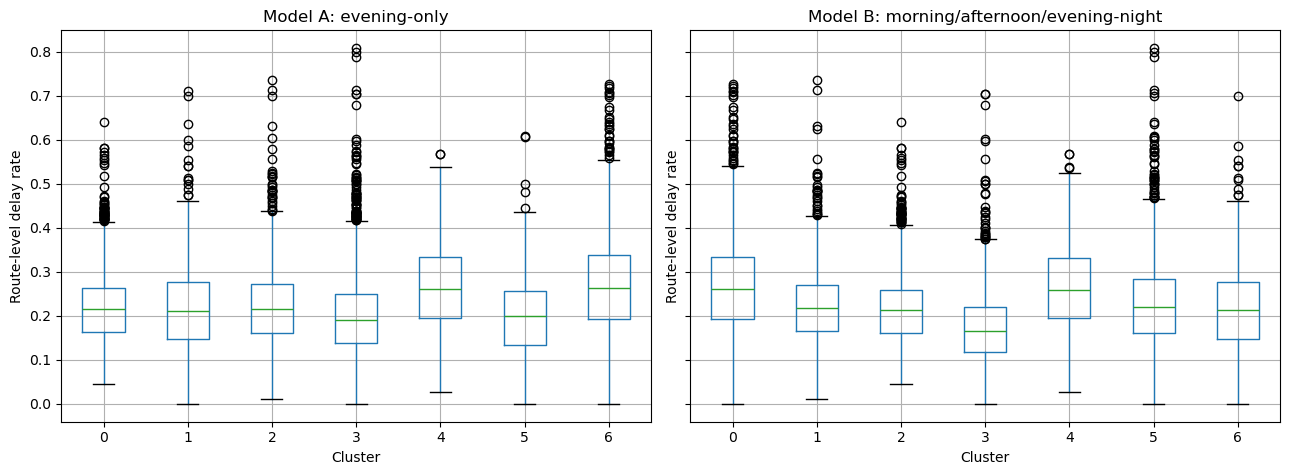

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, merged, title in [
    (axes[0], route_with_delays_a, "Model A: evening-only"),
    (axes[1], route_with_delays_b, "Model B: morning/afternoon/evening-night"),
]:
    merged.boxplot(column="delay_rate", by="cluster", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Route-level delay rate")
plt.suptitle("")
plt.tight_layout()
plt.show()


## Robustness checks


In [10]:
seeds = [0, 1, 2, 3, 4, 42, 100, 123, 2024, 2026]

def check_stability(X, reference_model, model_name):
    reference_labels = reference_model.labels_
    k = reference_model.n_clusters

    results = []

    for seed in seeds:
        labels = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        ).fit_predict(X)

        results.append({
            "seed": seed,
            "ARI": adjusted_rand_score(reference_labels, labels)
        })

    stability_df = pd.DataFrame(results)

    print(f"{model_name} initialization stability")
    display(stability_df.round(4))
    print("Mean ARI:", round(stability_df["ARI"].mean(), 4))

    return stability_df

stability_a = check_stability(X_a, model_a, "Model A")
stability_b = check_stability(X_b, model_b, "Model B")


Model A initialization stability


,seed,ARI
0,0,0.9970
1,1,0.9988
2,2,0.9953
3,3,0.6860
4,4,0.6986
5,42,1.0000
6,100,0.7048
7,123,0.6984
8,2024,0.7044
9,2026,0.9993


Mean ARI: 0.8483
Model B initialization stability


,seed,ARI
0,0,0.9918
1,1,0.9934
2,2,0.9985
3,3,0.9961
4,4,0.9911
5,42,1.0000
6,100,0.9920
7,123,0.6555
8,2024,0.9916
9,2026,0.9916


Mean ARI: 0.9602


In [11]:
threshold_rows = []
threshold_ari_rows = []

reference = route_b[KEYS + ["cluster"]].rename(
    columns={"cluster": "reference_cluster"}
)

for threshold in [30, 50, 100]:

    temp = route_data_all.loc[
        route_data_all["n_flights"] >= threshold
    ].copy()

    temp["flights_per_week"] = temp["n_flights"] / n_weeks
    temp["log_flights_per_week"] = np.log1p(temp["flights_per_week"])

    X_temp = StandardScaler().fit_transform(temp[FEATURES_B])

    labels = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=RANDOM_SEED,
        n_init=10
    ).fit_predict(X_temp)

    temp["cluster"] = labels

    threshold_rows.append({
        "threshold": threshold,
        "n_combinations": len(temp),
        "davies_bouldin": davies_bouldin_score(X_temp, labels),
        "silhouette": silhouette_score(
            X_temp,
            labels,
            sample_size=min(3000, len(temp)),
            random_state=RANDOM_SEED
        ),
    })

    shared = reference.merge(
        temp[KEYS + ["cluster"]],
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    threshold_ari_rows.append({
        "threshold": threshold,
        "shared_combinations": len(shared),
        "ARI_vs_30": adjusted_rand_score(
            shared["reference_cluster"],
            shared["cluster"]
        ),
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_ari_df = pd.DataFrame(threshold_ari_rows)

print("Model B — Threshold sensitivity")
display(threshold_df.round(3))

print("Cluster agreement with threshold 30")
display(threshold_ari_df.round(3))


Model B — Threshold sensitivity


,threshold,n_combinations,davies_bouldin,silhouette
0,30,9972,1.071,0.300
1,50,9184,1.063,0.287
2,100,7647,1.175,0.259


Cluster agreement with threshold 30


,threshold,shared_combinations,ARI_vs_30
0,30,9972,1.000
1,50,9184,0.888
2,100,7647,0.551


## Custom K-Means

In [12]:
def custom_kmeans(X, n_clusters=7, random_state=42,
                  n_init=10, max_iter=300, initial_centroids=None):

    X = np.asarray(X, dtype=float)
    n_samples, n_features = X.shape

    def initialize_centroids(rng):
        centroids = np.empty((n_clusters, n_features))

        first = rng.integers(n_samples)
        centroids[0] = X[first]

        closest_dist_sq = np.sum(
            (X - centroids[0]) ** 2, axis=1
        )

        for j in range(1, n_clusters):
            total = closest_dist_sq.sum()

            if total <= 0:
                idx = rng.integers(n_samples)
            else:
                probabilities = closest_dist_sq / total
                idx = rng.choice(n_samples, p=probabilities)

            centroids[j] = X[idx]

            new_dist_sq = np.sum(
                (X - centroids[j]) ** 2, axis=1
            )
            closest_dist_sq = np.minimum(
                closest_dist_sq, new_dist_sq
            )

        return centroids

    if initial_centroids is not None:
        initial_centroids = np.asarray(
            initial_centroids, dtype=float
        )

        if initial_centroids.shape != (n_clusters, n_features):
            raise ValueError(
                "initial_centroids must have shape "
                f"({n_clusters}, {n_features})"
            )

        n_init = 1

    best_inertia = np.inf
    best_result = None

    for run in range(n_init):

        if initial_centroids is not None:
            centroids = initial_centroids.copy()
        else:
            rng = np.random.default_rng(random_state + run)
            centroids = initialize_centroids(rng)

        previous_labels = None

        for iteration in range(max_iter):

            distances = np.sum(
                (X[:, None, :] - centroids[None, :, :]) ** 2,
                axis=2
            )
            labels = np.argmin(distances, axis=1)

            if previous_labels is not None and np.array_equal(
                labels, previous_labels
            ):
                break

            previous_labels = labels.copy()

            new_centroids = centroids.copy()

            for k in range(n_clusters):
                points = X[labels == k]

                if len(points) > 0:
                    new_centroids[k] = points.mean(axis=0)
                else:
                    farthest = np.argmax(
                        np.min(distances, axis=1)
                    )
                    new_centroids[k] = X[farthest]

            centroids = new_centroids

        distances = np.sum(
            (X[:, None, :] - centroids[None, :, :]) ** 2,
            axis=2
        )
        labels = np.argmin(distances, axis=1)

        inertia = np.sum(
            distances[np.arange(n_samples), labels]
        )

        if inertia < best_inertia:
            best_inertia = inertia
            best_result = {
                "labels": labels.copy(),
                "centroids": centroids.copy(),
                "inertia": inertia,
                "n_iter": iteration + 1
            }

    return best_result

print("Custom K-Means implementation defined successfully.")


Custom K-Means implementation defined successfully.


## Custom implementation validation

In [15]:
import time
start = time.perf_counter()

custom_result = custom_kmeans(
    X_b,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_SEED,
    n_init=10
)

custom_runtime = time.perf_counter() - start

start = time.perf_counter()

sklearn_model = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_SEED,
    n_init=10
)

sklearn_labels = sklearn_model.fit_predict(X_b)

sklearn_runtime = time.perf_counter() - start

ari = adjusted_rand_score(
    sklearn_labels,
    custom_result["labels"]
)

comparison = pd.DataFrame({
    "Metric": [
        "Inertia",
        "Iterations",
        "Runtime (seconds)"
    ],
    "Custom K-Means": [
        custom_result["inertia"],
        custom_result["n_iter"],
        custom_runtime
    ],
    "Scikit-learn K-Means": [
        sklearn_model.inertia_,
        sklearn_model.n_iter_,
        sklearn_runtime
    ]
})

print("Custom K-Means vs Scikit-learn")
display(comparison.round(4))

print(f"Adjusted Rand Index (ARI): {ari:.4f}")

print("\nCustom K-Means cluster sizes:")
display(
    pd.Series(custom_result["labels"])
    .value_counts()
    .sort_index()
)

print("Custom inertia:", round(custom_result["inertia"], 4))
print("Scikit-learn inertia:", round(sklearn_model.inertia_, 4))

print(
    "Relative inertia difference (%):",
    round(
        100 * (
            custom_result["inertia"] - sklearn_model.inertia_
        ) / sklearn_model.inertia_,
        3
    )
)

print(
    "Custom vs sklearn ARI:",
    round(
        adjusted_rand_score(
            custom_result["labels"],
            sklearn_model.labels_
        ),
        4
    )
)

for k in range(N_CLUSTERS):
    points = X_b[custom_result["labels"] == k]

    if len(points) > 0:
        difference = np.linalg.norm(
            custom_result["centroids"][k] - points.mean(axis=0)
        )
        print(f"Cluster {k}: centroid difference = {difference:.8f}")


Custom K-Means vs Scikit-learn


,Metric,Custom K-Means,Scikit-learn K-Means
0,Inertia,18915.5365,18916.0584
1,Iterations,22.0000,16.0000
2,Runtime (seconds),0.8015,0.3747


Adjusted Rand Index (ARI): 0.9949

Custom K-Means cluster sizes:


0    1831
1    3688
2     113
3     917
4     549
5    1199
6    1675
Name: count, dtype: int64

Custom inertia: 18915.5365
Scikit-learn inertia: 18916.0584
Relative inertia difference (%): -0.003
Custom vs sklearn ARI: 0.9949
Cluster 0: centroid difference = 0.00000000
Cluster 1: centroid difference = 0.00000000
Cluster 2: centroid difference = 0.00000000
Cluster 3: centroid difference = 0.00000000
Cluster 4: centroid difference = 0.00000000
Cluster 5: centroid difference = 0.00000000
Cluster 6: centroid difference = 0.00000000


## Controlled validation

In [16]:
rng = np.random.default_rng(RANDOM_SEED)

initial_indices = rng.choice(
    len(X_b),
    size=N_CLUSTERS,
    replace=False
)

initial_centroids = X_b[initial_indices].copy()

custom_controlled = custom_kmeans(
    X_b,
    n_clusters=N_CLUSTERS,
    initial_centroids=initial_centroids,
    max_iter=300
)

sklearn_controlled = KMeans(
    n_clusters=N_CLUSTERS,
    init=initial_centroids.copy(),
    n_init=1,
    max_iter=300,
    random_state=RANDOM_SEED
).fit(X_b)

controlled_ari = adjusted_rand_score(
    custom_controlled["labels"],
    sklearn_controlled.labels_
)

comparison_controlled = pd.DataFrame({
    "Metric": ["Inertia", "Iterations"],
    "Custom K-Means": [
        custom_controlled["inertia"],
        custom_controlled["n_iter"]
    ],
    "Scikit-learn K-Means": [
        sklearn_controlled.inertia_,
        sklearn_controlled.n_iter_
    ]
})

print("Controlled validation — identical initial centroids")
display(comparison_controlled.round(4))

print(f"Adjusted Rand Index (ARI): {controlled_ari:.4f}")


Controlled validation — identical initial centroids


,Metric,Custom K-Means,Scikit-learn K-Means
0,Inertia,19158.9142,19159.3934
1,Iterations,39.0000,30.0000


Adjusted Rand Index (ARI): 0.9904


## Hierarchical clustering

In [17]:
rng = np.random.default_rng(RANDOM_SEED)

sample_indices = rng.choice(
    len(X_b),
    size=min(3000, len(X_b)),
    replace=False
)

X_sample = X_b[sample_indices]

print(f"Sample size: {len(X_sample):,} route-airline combinations")

start = time.perf_counter()

hierarchical_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_sample)

hierarchical_runtime = time.perf_counter() - start

start = time.perf_counter()

kmeans_sample_model = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_SEED,
    n_init=10
)

kmeans_sample_labels = kmeans_sample_model.fit_predict(X_sample)

kmeans_sample_runtime = time.perf_counter() - start

comparison_hierarchical = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical (Ward)"],
    "Silhouette": [
        silhouette_score(X_sample, kmeans_sample_labels),
        silhouette_score(X_sample, hierarchical_labels)
    ],
    "Davies-Bouldin": [
        davies_bouldin_score(X_sample, kmeans_sample_labels),
        davies_bouldin_score(X_sample, hierarchical_labels)
    ],
    "Runtime (seconds)": [
        kmeans_sample_runtime,
        hierarchical_runtime
    ]
})

print("\nClustering method comparison")
display(comparison_hierarchical.round(4))

ari_hierarchical = adjusted_rand_score(
    kmeans_sample_labels,
    hierarchical_labels
)

print(f"\nARI between K-Means and Hierarchical: {ari_hierarchical:.4f}")

print("\nHierarchical cluster sizes:")
display(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
    .rename("n_routes")
)


Sample size: 3,000 route-airline combinations

Clustering method comparison


,Method,Silhouette,Davies-Bouldin,Runtime (seconds)
0,K-Means,0.2932,1.0607,0.3585
1,Hierarchical (Ward),0.2079,1.2270,0.2591



ARI between K-Means and Hierarchical: 0.4671

Hierarchical cluster sizes:


0    954
1    410
2    390
3    176
4    323
5    717
6     30
Name: n_routes, dtype: int64

## Cluster method profiles

In [18]:
sample_routes = route_data.iloc[sample_indices].copy()

sample_routes["kmeans_cluster"] = kmeans_sample_labels
sample_routes["hierarchical_cluster"] = hierarchical_labels

comparison_features = [
    "mean_distance",
    "n_flights",
    "morning_share",
    "afternoon_share",
    "evening_night_share",
    "weekend_share"
]

print("K-Means — Cluster characteristics")

kmeans_characteristics = (
    sample_routes.groupby("kmeans_cluster")[comparison_features]
    .mean()
    .round(3)
)

display(kmeans_characteristics)

print("\nK-Means cluster sizes")
display(
    sample_routes["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("n_routes")
)

print("\nHierarchical (Ward) — Cluster characteristics")

hierarchical_characteristics = (
    sample_routes.groupby("hierarchical_cluster")[comparison_features]
    .mean()
    .round(3)
)

display(hierarchical_characteristics)

print("\nHierarchical cluster sizes")
display(
    sample_routes["hierarchical_cluster"]
    .value_counts()
    .sort_index()
    .rename("n_routes")
)


K-Means — Cluster characteristics


,mean_distance,n_flights,morning_share,afternoon_share,evening_night_share,weekend_share
kmeans_cluster,,,,,,
0,825.898987,148.741,0.810,0.157,0.033,0.270
1,659.460022,622.718,0.430,0.341,0.229,0.270
2,745.697021,125.017,0.180,0.731,0.089,0.256
3,2221.053955,351.838,0.477,0.339,0.184,0.285
4,866.174011,73.599,0.374,0.458,0.167,0.475
5,1005.749023,158.983,0.071,0.171,0.757,0.278
6,1061.724976,48.300,0.402,0.536,0.063,0.911



K-Means cluster sizes


kmeans_cluster
0     474
1    1112
2     574
3     278
4     167
5     355
6      40
Name: n_routes, dtype: int64


Hierarchical (Ward) — Cluster characteristics


,mean_distance,n_flights,morning_share,afternoon_share,evening_night_share,weekend_share
hierarchical_cluster,,,,,,
0,661.934998,217.665,0.344,0.562,0.094,0.255
1,1036.237061,142.985,0.868,0.118,0.014,0.282
2,926.122986,185.274,0.077,0.218,0.705,0.285
3,905.926025,74.898,0.343,0.498,0.159,0.490
4,1924.310059,419.170,0.365,0.433,0.202,0.279
5,675.578979,718.033,0.415,0.297,0.288,0.270
6,1050.800049,42.033,0.390,0.537,0.072,0.970



Hierarchical cluster sizes


hierarchical_cluster
0    954
1    410
2    390
3    176
4    323
5    717
6     30
Name: n_routes, dtype: int64

## Statistical comparison

In [19]:
delay_groups = [
    group["delay_rate"].dropna().to_numpy()
    for _, group in route_with_delays_b.groupby("cluster")
]

H_stat, p_value = kruskal(*delay_groups)

N = sum(len(group) for group in delay_groups)
k = len(delay_groups)

epsilon_sq = max(0, (H_stat - k + 1) / (N - k))

print("Model B — Kruskal-Wallis test")
print(f"Number of routes: {N:,}")
print(f"Number of clusters: {k}")
print(f"H-statistic: {H_stat:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Epsilon-squared: {epsilon_sq:.4f}")

print("\nEta-squared from previous analysis:")
print(f"Eta-squared: {eta_b:.4f}")


Model B — Kruskal-Wallis test
Number of routes: 9,972
Number of clusters: 7
H-statistic: 838.4790
P-value: 7.45696e-178
Epsilon-squared: 0.0835

Eta-squared from previous analysis:
Eta-squared: 0.0885


## Delay causes

Delay cause distribution by cluster (%)


,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
cluster,,,,,
0,33.009998,7.43,16.059999,0.29,43.220001
1,38.380001,3.83,21.770000,0.21,35.799999
2,31.709999,6.57,19.270000,0.19,42.270000
3,38.790001,7.83,22.170000,0.14,31.070000
4,22.980000,4.52,23.260000,0.18,49.070000
5,30.370001,7.50,19.980000,0.16,41.990002
6,29.250000,6.54,24.170000,0.20,39.840000



Number of late flights per cluster


cluster
0     50579
1     74898
2    509012
3     43951
4      1459
5     53375
6      8869
Name: n_late_flights, dtype: int64

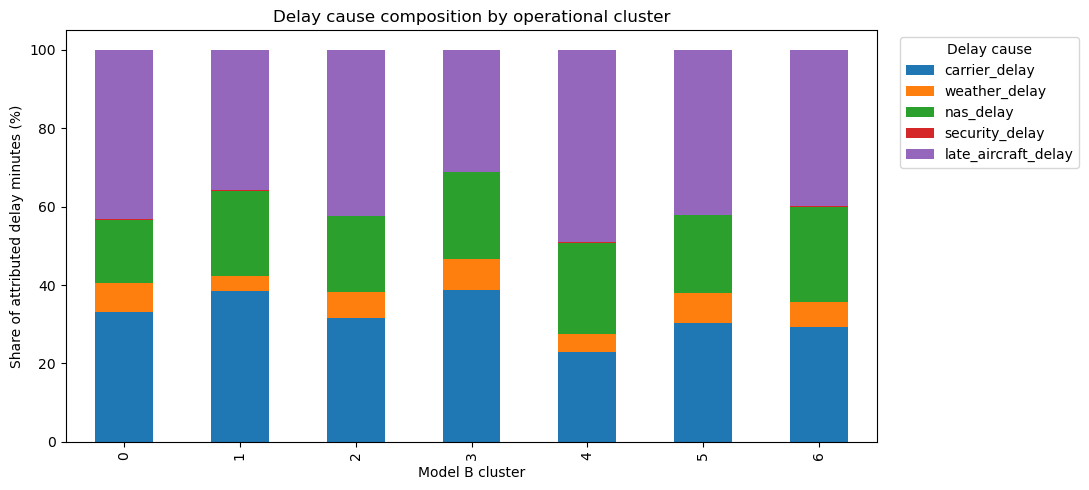

In [20]:
DELAY_CAUSES = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"
]

flights_with_clusters = flights.merge(
    route_b[KEYS + ["cluster"]],
    on=KEYS,
    how="inner",
    validate="many_to_one"
)

late_flights = flights_with_clusters.loc[
    (flights_with_clusters["delayed_15"] == 1)
    & flights_with_clusters[DELAY_CAUSES].notna().any(axis=1)
].copy()

late_flights[DELAY_CAUSES] = (
    late_flights[DELAY_CAUSES].fillna(0)
)

cause_minutes = (
    late_flights.groupby("cluster")[DELAY_CAUSES]
    .sum()
)

cause_shares = (
    cause_minutes.div(cause_minutes.sum(axis=1), axis=0) * 100
)

print("Delay cause distribution by cluster (%)")
display(cause_shares.round(2))

late_counts = (
    late_flights.groupby("cluster")
    .size()
    .rename("n_late_flights")
)

print("\nNumber of late flights per cluster")
display(late_counts)

ax = cause_shares.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

ax.set_title("Delay cause composition by operational cluster")
ax.set_xlabel("Model B cluster")
ax.set_ylabel("Share of attributed delay minutes (%)")
ax.legend(
    title="Delay cause",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


## Rolling clustering function

In [21]:
def fit_route_clusters(flights, months):

    months = sorted(set(months))

    if not months or months != list(range(1, max(months) + 1)):
        raise ValueError("Months must be consecutive, starting from January.")

    if max(months) > 12:
        raise ValueError("Months must be between 1 and 12.")

    train = flights.loc[
        flights["month"].isin(months)
    ].copy()

    train = train.loc[
        (train["cancelled"] == 0)
        & (train["diverted"] == 0)
        & (train["distance"] > 0)
        & (train["crs_elapsed_time"] > 0)
    ].copy()

    time_values = train["crs_dep_time"]

    valid_time = (
        time_values.notna()
        & time_values.between(0, 2400)
        & ((time_values % 100) < 60)
    )

    train = train.loc[valid_time].copy()

    train["dep_hour"] = (
        (train["crs_dep_time"] // 100) % 24
    ).astype(int)

    train["morning"] = (
        train["dep_hour"].between(5, 11)
    ).astype(int)

    train["evening_night"] = (
        (train["dep_hour"] >= 18)
        | (train["dep_hour"] < 5)
    ).astype(int)

    train["weekend"] = (
        train["day_of_week"].isin([6, 7])
    ).astype(int)

    profiles = (
        train.groupby(KEYS, observed=True)
        .agg(
            n_flights=("distance", "size"),
            mean_distance=("distance", "mean"),
            morning_share=("morning", "mean"),
            evening_night_share=("evening_night", "mean"),
            weekend_share=("weekend", "mean")
        )
        .reset_index()
    )

    start_date = pd.Timestamp("2024-01-01")

    end_date = (
        pd.Timestamp("2025-01-01")
        if max(months) == 12
        else pd.Timestamp(2024, max(months) + 1, 1)
    )

    n_weeks = (end_date - start_date).days / 7

    profiles["flights_per_week"] = (
        profiles["n_flights"] / n_weeks
    )

    min_flights_per_week = 30 / 26

    profiles = profiles.loc[
        profiles["flights_per_week"] >= min_flights_per_week
    ].copy()

    profiles["log_flights_per_week"] = np.log1p(
        profiles["flights_per_week"]
    )

    features = [
        "mean_distance",
        "log_flights_per_week",
        "morning_share",
        "evening_night_share",
        "weekend_share"
    ]

    if len(profiles) < N_CLUSTERS:
        raise ValueError("Not enough route profiles for clustering.")

    scaler = StandardScaler()
    X = scaler.fit_transform(profiles[features])

    model = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=RANDOM_SEED,
        n_init=10
    )

    profiles["cluster"] = model.fit_predict(X)

    lookup = profiles[
        KEYS + ["cluster"]
    ].copy()

    return {
        "lookup": lookup,
        "profiles": profiles,
        "model": model,
        "scaler": scaler,
        "features": features,
        "n_weeks": n_weeks
    }

print("Reusable RQ1 clustering function defined successfully.")

all_flights = load_flights(CLEAN_PARQUET)

rq1_june = fit_route_clusters(
    all_flights, months=list(range(1, 7))
)

print("Training period:", rq1_june["n_weeks"], "weeks")

print("Number of route-airline combinations:",
      len(rq1_june["lookup"]))

print("\nCluster sizes:")
display(
    rq1_june["lookup"]["cluster"]
    .value_counts()
    .sort_index()
)

shared = route_b[KEYS + ["cluster"]].merge(
    rq1_june["lookup"],
    on=KEYS,
    suffixes=("_original", "_function"),
    validate="one_to_one"
)

ari = adjusted_rand_score(
    shared["cluster_original"],
    shared["cluster_function"]
)

print(f"\nAgreement with existing Model B (ARI): {ari:.4f}")


Reusable RQ1 clustering function defined successfully.
Training period: 26.0 weeks
Number of route-airline combinations: 9972

Cluster sizes:


cluster
0    1198
1     915
2    3684
3    1695
4     114
5    1819
6     547
Name: count, dtype: int64


Agreement with existing Model B (ARI): 1.0000


## Rolling-window checks

In [22]:
rolling_results = []

for end_month in [6, 7, 8]:

    result = fit_route_clusters(
        all_flights,
        months=list(range(1, end_month + 1))
    )

    rolling_results.append({
        "training_months": f"January–{pd.Timestamp(2024, end_month, 1).strftime('%B')}",
        "n_weeks": result["n_weeks"],
        "n_routes": len(result["lookup"]),
        "n_clusters": result["lookup"]["cluster"].nunique()
    })

rolling_df = pd.DataFrame(rolling_results)

print("RQ1 rolling-window validation")
display(rolling_df.round(2))


RQ1 rolling-window validation


,training_months,n_weeks,n_routes,n_clusters
0,January–June,26.00,9972,7
1,January–July,30.43,10187,7
2,January–August,34.86,10226,7


## Assign clusters to future flights

In [23]:
def assign_route_clusters(future_flights, rq1_result):
    result = future_flights.merge(
        rq1_result["lookup"], on=KEYS, how="left", validate="many_to_one"
    )
    result["route_cluster"] = (
        result.pop("cluster").astype("Int64").astype("string").fillna("unknown")
    )
    return result


## July coverage

In [25]:
july_flights = all_flights.loc[
    all_flights["month"] == 7
].copy()

july_rq3 = assign_route_clusters(july_flights, rq1_june)

coverage = july_rq3["route_cluster"].value_counts().rename("flights")

print("July cluster coverage")
display(coverage)

print(f"Unknown routes: {(july_rq3['route_cluster'] == 'unknown').mean():.2%}")


July cluster coverage


route_cluster
2          411653
1           66131
3           47467
5           45881
0           37243
unknown     16907
6            8281
4            1046
Name: flights, dtype: Int64

Unknown routes: 2.66%


## Historical delay features

In [27]:
def calculate_cluster_delay_rates(historical_flights, rq1_result):

    historical = assign_route_clusters(
        historical_flights,
        rq1_result
    )

    historical = historical.loc[
        (historical["cancelled"] == 0)
        & (historical["diverted"] == 0)
        & historical["arr_delay"].notna()
        & (historical["route_cluster"] != "unknown")
    ].copy()

    historical["delayed_15"] = (
        historical["arr_delay"] >= 15
    ).astype(int)

    cluster_rates = (
        historical.groupby("route_cluster")["delayed_15"]
        .agg(
            historical_delay_rate="mean",
            n_historical_flights="size"
        )
        .reset_index()
    )

    return cluster_rates

historical_flights = all_flights.loc[
    all_flights["month"].between(1, 6)
].copy()

historical_cluster_rates = calculate_cluster_delay_rates(
    historical_flights,
    rq1_june
)

print("Historical cluster delay rates (January-June)")
display(historical_cluster_rates.round(4))

july_rq3 = july_rq3.merge(
    historical_cluster_rates[
        ["route_cluster", "historical_delay_rate"]
    ],
    on="route_cluster",
    how="left",
    validate="many_to_one"
)

eligible_history = historical_flights.loc[
    (historical_flights["cancelled"] == 0)
    & (historical_flights["diverted"] == 0)
    & historical_flights["arr_delay"].notna()
]

overall_historical_rate = (
    eligible_history["arr_delay"] >= 15
).mean()

july_rq3["historical_delay_rate"] = (
    july_rq3["historical_delay_rate"]
    .fillna(overall_historical_rate)
)

print("\nOverall historical delay rate:",
      round(overall_historical_rate, 4))

print("\nJuly flights with missing RQ1 delay-rate features:",
      july_rq3["historical_delay_rate"].isna().sum())


Historical cluster delay rates (January-June)


,route_cluster,historical_delay_rate,n_historical_flights
0,0,0.2697,187541
1,1,0.2215,338179
2,2,0.2192,2321870
3,3,0.1740,252635
4,4,0.2685,5433
5,5,0.2288,233248
6,6,0.2293,38674



Overall historical delay rate: 0.22

July flights with missing RQ1 delay-rate features: 0


## Export results

July features use January–June history only. For RQ3 model training, historical delay-rate features must be calculated without using each training observation’s own or future outcomes.


In [30]:
output_dir = TABLES_DIR
output_dir.mkdir(parents=True, exist_ok=True)

route_a.to_csv(
    output_dir / "02_route_clusters_model_a.csv",
    index=False
)

route_b.to_csv(
    output_dir / "02_route_clusters_model_b.csv",
    index=False
)

cluster_delays_a.to_csv(
    output_dir / "02_cluster_delay_summary_model_a.csv"
)

cluster_delays_b.to_csv(
    output_dir / "02_cluster_delay_summary_model_b.csv"
)

evaluation_a.to_csv(
    output_dir / "02_evaluation_model_a.csv",
    index=False
)

evaluation_b.to_csv(
    output_dir / "02_evaluation_model_b.csv",
    index=False
)

stability_a.to_csv(
    output_dir / "02_stability_model_a.csv",
    index=False
)

stability_b.to_csv(
    output_dir / "02_stability_model_b.csv",
    index=False
)

threshold_df.to_csv(
    output_dir / "02_threshold_sensitivity.csv",
    index=False
)

threshold_ari_df.to_csv(
    output_dir / "02_threshold_ari.csv",
    index=False
)

comparison_hierarchical.to_csv(
    output_dir / "02_hierarchical_comparison.csv",
    index=False
)

cause_shares.to_csv(
    output_dir / "02_delay_cause_shares.csv"
)

route_lookup = rq1_june["lookup"].rename(
    columns={"cluster": "route_cluster"}
).copy()

route_lookup.to_csv(
    output_dir / "rq1_route_clusters_jan_jun.csv",
    index=False
)

historical_cluster_rates.to_csv(
    output_dir / "rq1_cluster_delay_rates_jan_jun.csv",
    index=False
)

rolling_df.to_csv(
    output_dir / "02_rolling_window_validation.csv",
    index=False
)

print("RQ1 tables exported successfully.")
print("Number of CSV files exported:", 15)


RQ1 tables exported successfully.
Number of CSV files exported: 15
